粗体: C:/Windows/Fonts/msyhbd.ttc
常规: C:/Windows/Fonts/msyh.ttc
尺寸: (1089, 793) | 背景色: (26, 30, 67)
已保存: C:\Users\28349\数据可视化\chart_recreated.png


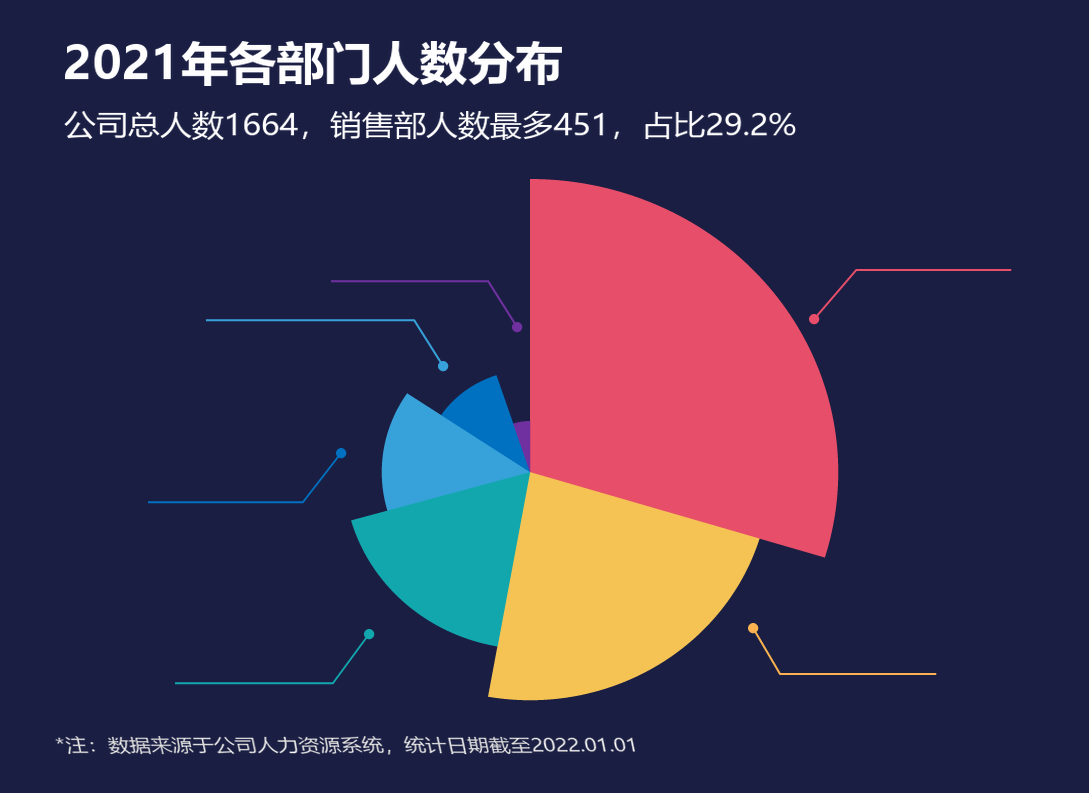

C:\Users\28349\数据可视化\chart_recreated.png

In [1]:
# ── 1. 依赖与全局配置 ─────────────────────────────────────────────
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display, FileLink
from pathlib import Path
import os
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
# 画布（与原图深蓝图表区一致）
W, H = 1089, 793
S = 4                              # 超采样倍数，保证弧线/折线平滑

# 颜色（全部取自原图像素）
NAVY      = (26, 30, 67)           # 背景 #1A1E43
WHITE     = (255, 255, 255)
NOTE_GRAY = (217, 217, 217)

# 部门、占比、扇区颜色
DATA = [
    ("销售部", 29.2, (231, 78, 105)),   # 珊瑚红
    ("采购部", 22.7, (245, 195, 83)),   # 明黄
    ("工程部", 17.5, (17, 167, 173)),   # 青绿
    ("财务部", 13.6, (55, 162, 218)),   # 浅蓝
    ("行政部", 10.3, (0, 112, 192)),    # 深蓝
    ("人力部",  5.0, (112, 48, 160)),   # 紫
]

# 扇形几何：同心椭圆扇形，从 12 点方向顺时针
CX, CY  = 530, 472                          # 共同中心
STRETCH = 1.0514                            # 水平半轴 / 垂直半轴
RADII   = [293, 228, 177, 141, 102, 51]     # 各扇区垂直半轴（随占比递减）
TOTAL   = sum(v for _, v, _ in DATA)         # 合计 98.3%，饼图自动归一到 360°
SWEEPS  = [v / TOTAL * 360 for _, v, _ in DATA]

# 引导线：(颜色, 折线拐点, 末端圆点圆心)
LEADERS = [
    ((112, 48, 160), [(331, 281), (488, 281), (517, 327)], (517, 327)),
    ((55, 162, 218), [(206, 320), (414, 320), (443, 366)], (443, 366)),
    ((0, 112, 192),  [(148, 502), (303, 502), (341, 453)], (341, 453)),
    ((17, 167, 173), [(175, 683), (333, 683), (369, 634)], (369, 634)),
    ((231, 78, 105), [(1011, 270), (856, 270), (814, 319)], (814, 319)),
    ((250, 178, 80), [(936, 674), (780, 674), (753, 628)], (753, 628)),  # 该线用橙色
]
LINE_W, DOT_R = 2, 5

# 文字内容 + 原图墨迹包围盒 (left, top, right, bottom)
TITLE    = "2021年各部门人数分布"
SUBTITLE = "公司总人数1664，销售部人数最多451，占比29.2%"
NOTE     = "*注：数据来源于公司人力资源系统，统计日期截至2022.01.01"
BOX_TITLE = (65, 41, 562, 86)
BOX_SUB   = (64, 111, 796, 140)
BOX_NOTE  = (55, 736, 636, 755)

OUT_PATH = Path.cwd() / "chart_recreated.png"
def find_font(candidates):
    for p in candidates:
        if os.path.isfile(p):
            return p
    raise FileNotFoundError(
        "没找到中文字体。请手动指定路径，例如：\n"
        'F_BOLD = "C:/Windows/Fonts/msyhbd.ttc"\n'
        'F_REG  = "C:/Windows/Fonts/msyh.ttc"'
    )

F_BOLD = find_font([
    "C:/Windows/Fonts/msyhbd.ttc",
    "C:/Windows/Fonts/Noto Sans SC Bold (TrueType).otf",
    "C:/Windows/Fonts/simhei.ttf",
    "/System/Library/Fonts/PingFang.ttc",
    "/usr/share/fonts/opentype/noto/NotoSansCJK-Bold.ttc",
])
F_REG = find_font([
    "C:/Windows/Fonts/msyh.ttc",
    "C:/Windows/Fonts/Noto Sans SC (TrueType).otf",
    "C:/Windows/Fonts/Deng.ttf",
    "/System/Library/Fonts/PingFang.ttc",
    "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc",
])
print("粗体:", F_BOLD)
print("常规:", F_REG)
def draw_text_fit(canvas, text, font_path, size, box, color, shear=0.0):
    font = ImageFont.truetype(font_path, size)
    bb = font.getbbox(text)
    pad = 12
    layer = Image.new("RGBA", (bb[2] - bb[0] + pad * 2,
                               bb[3] - bb[1] + pad * 2), (0, 0, 0, 0))
    ImageDraw.Draw(layer).text((pad - bb[0], pad - bb[1]), text,
                               font=font, fill=color + (255,))

    if shear:                                   # 斜体：水平方向随 y 偏移
        w, h = layer.size
        nw = w + int(shear * h) + 4
        layer = layer.transform((nw, h), Image.AFFINE,
                                (1, -shear, shear * h, 0, 1, 0),
                                resample=Image.BICUBIC)

    layer = layer.crop(layer.getchannel("A").getbbox())
    tw, th = box[2] - box[0], box[3] - box[1]
    layer = layer.resize((tw, th), Image.LANCZOS)
    canvas.paste(layer, (box[0], box[1]), layer)
def render():
    big = Image.new("RGB", (W * S, H * S), NAVY)
    d = ImageDraw.Draw(big)

    # 玫瑰扇形
    angle = 270.0
    for (_, _, color), b, sweep in zip(DATA, RADII, SWEEPS):
        a = b * STRETCH
        xy = (round((CX - a) * S), round((CY - b) * S),
              round((CX + a) * S), round((CY + b) * S))
        d.pieslice(xy, start=angle, end=angle + sweep, fill=color)
        angle += sweep

    # 折线引导线 + 末端圆点
    for color, pts, dot in LEADERS:
        d.line([(round(x * S), round(y * S)) for x, y in pts],
               fill=color, width=LINE_W * S, joint="curve")
        dx, dy = dot
        d.ellipse((round((dx - DOT_R) * S), round((dy - DOT_R) * S),
                   round((dx + DOT_R) * S), round((dy + DOT_R) * S)),
                  fill=color)

    canvas = big.resize((W, H), Image.BOX)

    draw_text_fit(canvas, TITLE,    F_BOLD, 47, BOX_TITLE, WHITE)
    draw_text_fit(canvas, SUBTITLE, F_REG,  31, BOX_SUB,   WHITE)
    draw_text_fit(canvas, NOTE,     F_REG,  21, BOX_NOTE,  NOTE_GRAY, shear=0.18)
    return canvas
canvas = render()
canvas.save(OUT_PATH)
print("尺寸:", canvas.size, "| 背景色:", canvas.getpixel((1000, 100)))
print("已保存:", OUT_PATH)

display(canvas)                       # 在 Notebook 中直接显示
try:
    display(FileLink(str(OUT_PATH)))  # 附带下载链接（部分内核不支持会自动跳过）
except Exception:
    pass

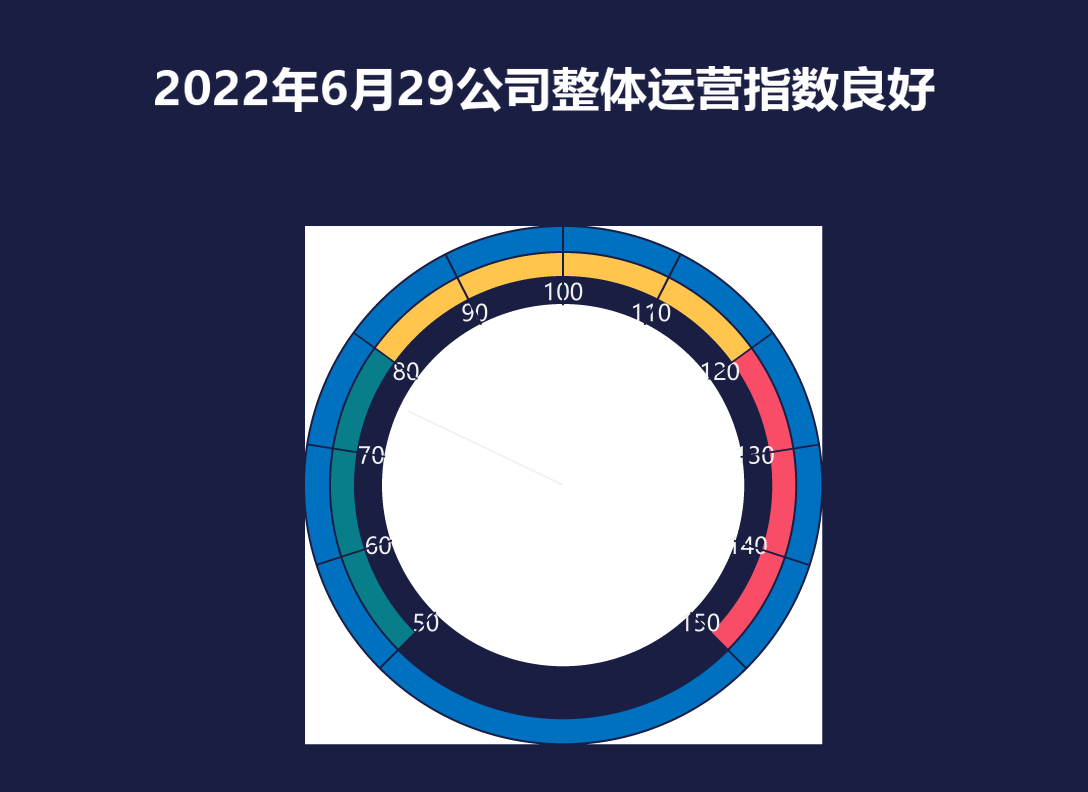

In [2]:
import math
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
S = 4
N, W, G = (26, 30, 67), (255, 255, 255), (242, 242, 242)
B, Y, T, R = (0, 112, 192), (255, 197, 77), (8, 126, 139), (249, 76, 102)
cx, cy = 563, 485
im = Image.new('RGB', (1088 * S, 792 * S), N)
d = ImageDraw.Draw(im)

def circle(r, c):
    d.ellipse([(cx-r)*S, (cy-r)*S, (cx+r)*S, (cy+r)*S], fill=c)

def sector(r, a, b, c):
    d.pieslice([(cx-r)*S, (cy-r)*S, (cx+r)*S, (cy+r)*S], start=a, end=b, fill=c)

def ray(a, r0, r1, c, w):
    t = math.radians(a)
    d.line([(cx+r0*math.cos(t))*S, (cy+r0*math.sin(t))*S,
            (cx+r1*math.cos(t))*S, (cy+r1*math.sin(t))*S], fill=c, width=w*S)

d.rectangle([305*S, 226*S, 822*S, 744*S], fill=W)
circle(260, N); circle(258, B); circle(234, N)
for a, b, c in [(135, 216, T), (216, 324, Y), (324, 405, R)]:
    sector(232, a, b, c)
circle(209, N); circle(181, W)

f = ImageFont.truetype('C:/Windows/Fonts/msyh.ttc', 23 * S)
for k in range(11):
    a = math.radians(135 + 27*k)
    d.text(((cx+194*math.cos(a))*S, (cy+194*math.sin(a))*S),
           str(50+10*k), font=f, fill=G, anchor='mm')
for k in range(11):
    ray(135 + 27*k, 180, 258, N, 2)
d.line([cx*S, cy*S, 408*S, 411*S], fill=G, width=2*S)

out = im.resize((1088, 792), Image.BOX)
f = ImageFont.truetype('C:/Windows/Fonts/msyhbd.ttc', 47)
tmp = Image.new('RGBA', (1000, 90), (0, 0, 0, 0))
ImageDraw.Draw(tmp).text((10, 4), '2022年6月29公司整体运营指数良好', font=f, fill=W)
tmp = tmp.crop(tmp.getchannel('A').getbbox()).resize((780, 46), Image.LANCZOS)
out.paste(tmp, (155, 66), tmp)
out.save('gauge_chart.png')
display(out)

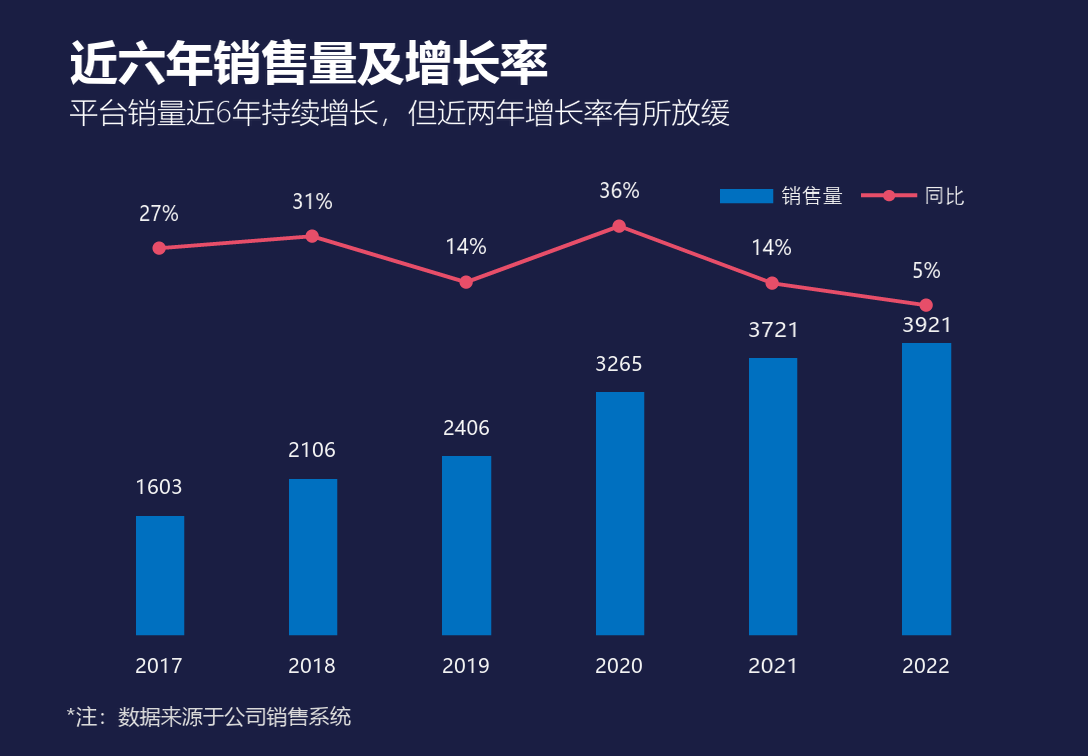

In [3]:
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
W, H, S = 1088, 756, 4
N, B, R, WT, GY, NT = (26,30,67), (0,112,192), (231,78,105), (255,255,255), (242,242,242), (217,217,217)
P = 'C:/Windows/Fonts/'
fp = lambda n: next((p for p in [P+n, '/System/Library/Fonts/PingFang.ttc', '/usr/share/fonts/truetype/wqy/wqy-microhei.ttc'] if Path(p).exists()), P+n)
BD, RG, LT, DG = [fp(f) for f in ('msyhbd.ttc','msyh.ttc','msyhl.ttc','Deng.ttf')]
F = lambda p, s: ImageFont.truetype(p, s)
im = Image.new('RGB', (W*S, H*S), N)
d = ImageDraw.Draw(im)
sc = lambda *v: [round(x*S) for x in v]

BARS = [(136,516,183,634),(289,479,336,634),(442,456,490,634),(596,392,643,634),(749,358,796,634),(902,343,950,634)]
PTS = [(159,248),(312,236),(466,282),(619,226),(772,283),(926,305)]
for x0,y0,x1,y1 in BARS: d.rectangle(sc(x0,y0,x1+1,y1+1), fill=B)
d.line([(round(x*S), round(y*S)) for x,y in PTS], fill=R, width=4*S)
for x,y in PTS: d.ellipse(sc(x-6.5,y-6.5,x+6.5,y+6.5), fill=R)
d.rectangle(sc(720,189,773,203), fill=B)
d.line(sc(861,195,917,195), fill=R, width=4*S)
d.ellipse(sc(883,190,895,201), fill=R)
out = im.resize((W,H), Image.BOX)

def put(s, box, p, size, color):
    t = Image.new('RGBA', (1400,140), (0,0,0,0))
    ImageDraw.Draw(t).text((10,0), s, font=F(p,size), fill=(*color,255))
    t = t.crop(t.getchannel('A').getbbox())
    x0,y0,x1,y1 = box
    t = t.resize((x1-x0+1, y1-y0+1), Image.LANCZOS)
    out.paste(t, (x0,y0), t)

put('近六年销售量及增长率', (70,39,547,85), BD, 47, WT)
put('平台销量近6年持续增长，但近两年增长率有所放缓', (70,99,729,126), LT, 30, WT)
put('销售量', (781,186,842,204), DG, 20, GY)
put('同比', (926,186,963,204), DG, 20, GY)
put('*注：数据来源于公司销售系统', (66,706,350,726), RG, 21, NT)
PCT, VAL = ['27%','31%','14%','36%','14%','5%'], ['1603','2106','2406','3265','3721','3921']
PY, VY, PW, VW, CX = [205,193,238,182,239,262], [479,442,420,356,322,317], [38,39,39,39,38,27], [45,46,45,46,47,46], [159,312,466,619,772,926]
for k in range(6):
    put(PCT[k], (CX[k]-PW[k]//2, PY[k], CX[k]-PW[k]//2+PW[k]-1, PY[k]+15), RG, 20, GY)
    put(VAL[k], (CX[k]-VW[k]//2, VY[k], CX[k]-VW[k]//2+VW[k]-1, VY[k]+14), RG, 20, GY)
    put(str(2017+k), (CX[k]-23, 658, CX[k]+22, 672), RG, 20, GY)
out.save('sales_chart.png')
display(out)


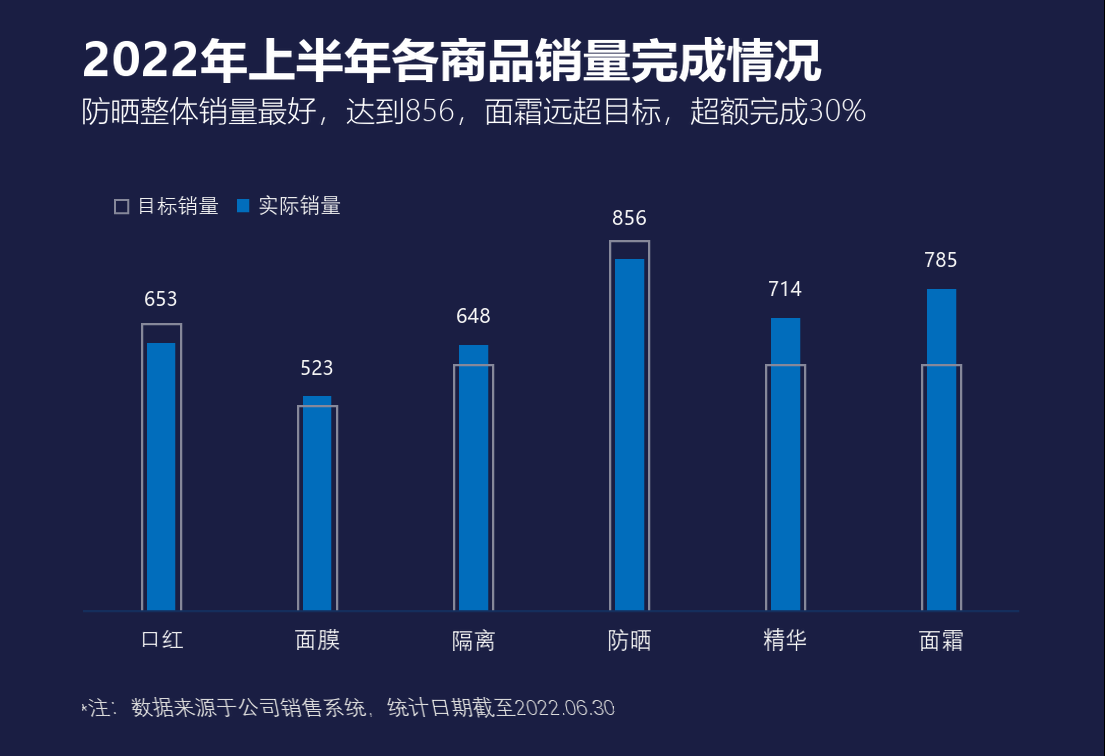

In [4]:
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
W, H, S = 1105, 756, 4
N, B, G, AX, WT, GY, NT = (26,30,67), (1,109,188), (134,136,154), (21,46,92), (255,255,255), (242,242,242), (217,217,217)
P = 'C:/Windows/Fonts/'
fp = lambda n: next((p for p in [P+n, '/System/Library/Fonts/PingFang.ttc', '/usr/share/fonts/truetype/wqy/wqy-microhei.ttc'] if Path(p).exists()), P+n)
BD, RG, LT, DG = [fp(f) for f in ('msyhbd.ttc','msyh.ttc','msyhl.ttc','Deng.ttf')]
F = lambda p, s: ImageFont.truetype(p, s)
im = Image.new('RGB', (W*S, H*S), N)
d = ImageDraw.Draw(im)
sc = lambda *v: [round(x*S) for x in v]

d.rectangle(sc(83,610,1019,612), fill=AX)
BX, BY, BW = [147,303,459,615,771,927], [343,396,345,259,318,289], [28,28,29,29,29,29]
FX, FY = [141,297,453,609,765,921], [323,405,364,240,364,364]
for x,y,w in zip(BX,BY,BW): d.rectangle(sc(x,y,x+w,610), fill=B)
for x,y in zip(FX,FY):
    d.rectangle(sc(x,y,x+2,610), fill=G)
    d.rectangle(sc(x+39,y,x+41,610), fill=G)
    d.rectangle(sc(x,y,x+41,y+2), fill=G)
d.rectangle(sc(114,199,129,214), outline=G, width=2*S)
d.rectangle(sc(237,199,249,212), fill=B)
out = im.resize((W,H), Image.BOX)
ImageDraw.Draw(out).line([(1104,0),(1104,755)], fill=(0,0,0))

def put(s, box, p, size, color, shear=0):
    t = Image.new('RGBA', (1500,140), (0,0,0,0))
    ImageDraw.Draw(t).text((10,0), s, font=F(p,size), fill=(*color,255))
    t = t.crop(t.getchannel('A').getbbox())
    if shear: t = t.transform((t.width+int(shear*t.height)+4, t.height), Image.AFFINE, (1,-shear,shear*t.height,0,1,0), Image.BICUBIC)
    x0,y0,x1,y1 = box
    t = t.resize((x1-x0+1, y1-y0+1), Image.LANCZOS)
    out.paste(t, (x0,y0), t)

put('2022年上半年各商品销量完成情况', (84,37,821,82), BD, 47, WT)
put('防晒整体销量最好，达到856，面霜远超目标，超额完成30%', (83,97,865,124), LT, 30, WT)
put('目标销量', (140,196,218,214), DG, 20, GY)
put('实际销量', (259,195,340,214), DG, 20, GY)
put('*注：数据来源于公司销售系统，统计日期截至2022.06.30', (82,697,623,717), DG, 21, NT, 0.20)
VAL, VB = ['653','523','648','856','714','785'], [(145,291,176,305),(301,360,332,374),(457,308,489,322),(612,210,645,224),(769,281,801,295),(925,252,956,266)]
CAT, CB = ['口红','面膜','隔离','防晒','精华','面霜'], [(142,630,182,648),(295,629,339,649),(452,629,494,650),(608,629,650,650),(763,628,806,650),(919,630,962,650)]
for k in range(6):
    put(VAL[k], VB[k], RG, 20, GY)
    put(CAT[k], CB[k], DG, 20, GY)
out.save('target_chart.png')
display(out)


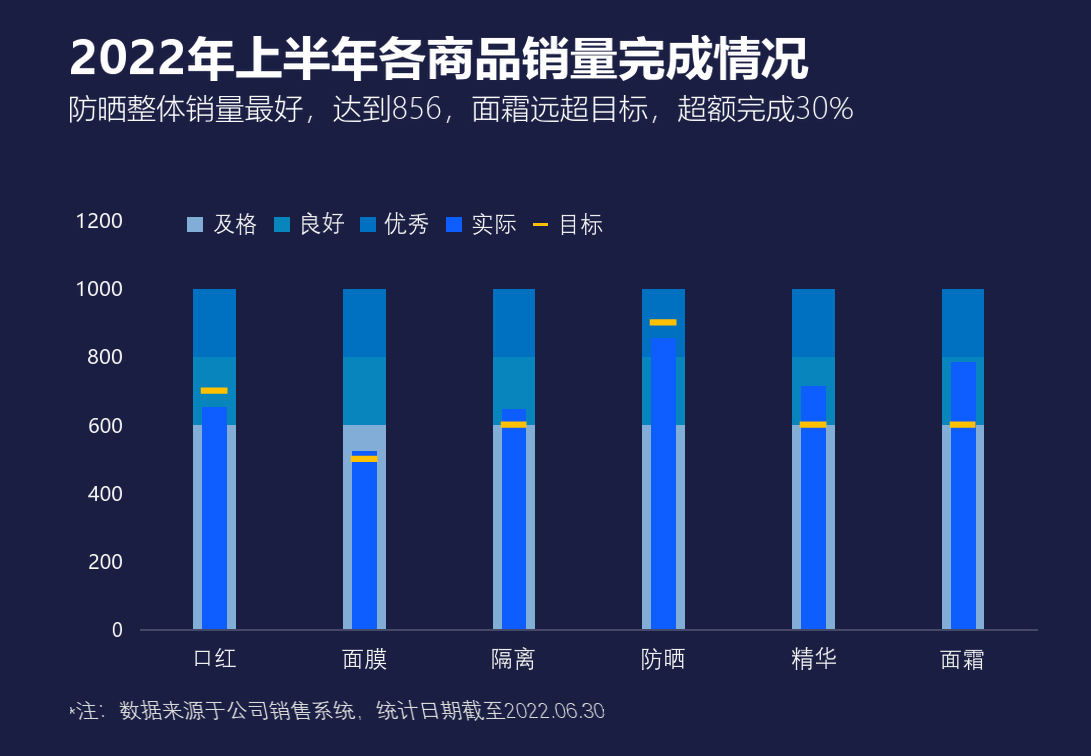

In [5]:
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
W, H, S = 1091, 756, 4
N, L, C, D, V, Y = (26,30,67), (130,173,215), (8,133,188), (0,112,192), (14,93,255), (255,192,0)
AX, WT, GY, NT = (69,72,102), (255,255,255), (242,242,242), (217,217,217)
P = 'C:/Windows/Fonts/'
fp = lambda n: next((p for p in [P+n, '/System/Library/Fonts/PingFang.ttc', '/usr/share/fonts/truetype/wqy/wqy-microhei.ttc'] if Path(p).exists()), P+n)
BD, LT, DG, RG = [fp(f) for f in ('msyhbd.ttc','msyhl.ttc','Deng.ttf','msyh.ttc')]
F = lambda p, s: ImageFont.truetype(p, s)
im = Image.new('RGB', (W*S, H*S), N)
d = ImageDraw.Draw(im)
def rect(x0,y0,x1,y1,c): d.rectangle([x0*S, y0*S, (x1+1)*S-1, (y1+1)*S-1], fill=c)

rect(140,629,1037,630,AX)
BX, EX = [193,343,493,642,792,942], [235,385,534,684,834,983]
VX, VE, VY = [202,352,502,651,801,951], [226,376,525,675,825,975], [407,451,409,338,386,362]
for a,b in zip(BX,EX):
    rect(a,289,b,628,L); rect(a,289,b,424,C); rect(a,289,b,356,D)
for a,b,y in zip(VX,VE,VY): rect(a,y,b,628,V)
for (x,w),q in zip([(201,26),(351,26),(501,25),(650,26),(800,26),(950,25)], [1550,1823,1686,1277,1686,1686]):
    d.rectangle([x*S-1, q, (x+w)*S+1, q+24], fill=Y)
for x,c in [(187,L),(274,C),(360,D),(446,V)]: rect(x,217,x+15,231,c)
rect(533,223,547,225,Y)
out = im.resize((W,H), Image.BOX)

def put(s, box, p, size, color, shear=0):
    t = Image.new('RGBA', (1500,140), (0,0,0,0))
    ImageDraw.Draw(t).text((10,0), s, font=F(p,size), fill=(*color,255))
    t = t.crop(t.getchannel('A').getbbox())
    if shear: t = t.transform((t.width+int(shear*t.height)+4, t.height), Image.AFFINE, (1,-shear,shear*t.height,0,1,0), Image.BICUBIC)
    x0,y0,x1,y1 = box
    t = t.resize((x1-x0+1, y1-y0+1), Image.LANCZOS)
    out.paste(t, (x0,y0), t)

put('2022年上半年各商品销量完成情况', (71,35,808,80), BD, 47, WT)
put('防晒整体销量最好，达到856，面霜远超目标，超额完成30%', (70,95,852,122), LT, 28, WT)
for s,b in [('及格',(213,213,256,234)),('良好',(301,212,343,234)),('优秀',(384,212,428,234)),('实际',(472,213,515,234)),('目标',(561,213,602,234))]: put(s,b,DG,23,GY)
for s,b in zip(['1200','1000','800','600','400','200','0'], [(77,213,121,227),(77,281,121,295),(88,349,121,363),(89,418,121,432),(88,486,121,500),(89,554,121,568),(112,622,121,636)]): put(s,b,RG,22,GY)
for s,b in zip(['口红','面膜','隔离','防晒','精华','面霜'], [(195,648,235,667),(342,648,386,669),(492,647,534,669),(642,648,684,669),(791,647,835,669),(940,649,983,669)]): put(s,b,DG,23,GY)
put('*注：数据来源于公司销售系统，统计日期截至2022.06.30', (70,700,613,720), DG, 21, NT, 0.20)
out.save('bullet_chart.png')
display(out)


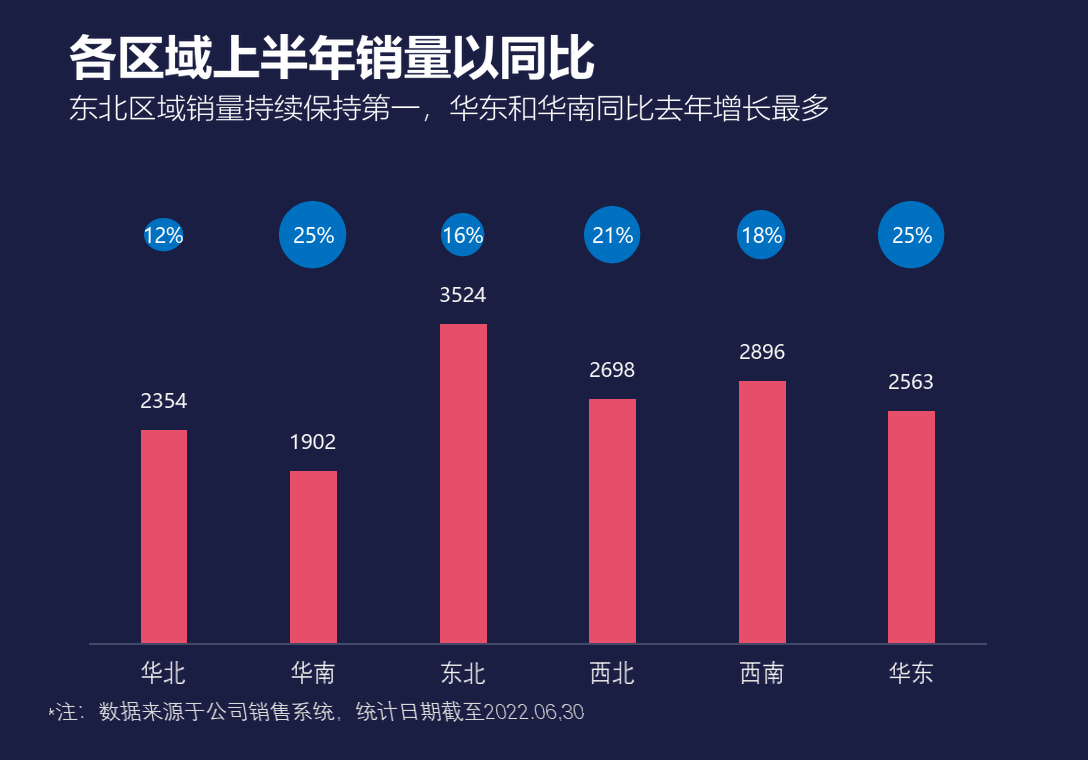

In [6]:
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
W,H,S = 1088,760,4
N,WT,GY,NT,AX = (26,30,67),(255,255,255),(242,242,242),(217,217,217),(69,72,102)
P='C:/Windows/Fonts/'
fp=lambda n:next((p for p in [P+n,'/System/Library/Fonts/PingFang.ttc','/usr/share/fonts/truetype/wqy/wqy-microhei.ttc'] if Path(p).exists()),P+n)
BD,RG,LT,DG,NM=[fp(f) for f in ('msyhbd.ttc','msyh.ttc','msyhl.ttc','Deng.ttf','msyh.ttc')]
F=lambda p,s:ImageFont.truetype(p,s)
im=Image.new('RGB',(W*S,H*S),N);d=ImageDraw.Draw(im)
def R(x0,y0,x1,y1,c):d.rectangle([x0*S,y0*S,(x1+1)*S-1,(y1+1)*S-1],fill=c)
def E(x0,y0,x1,y1,c,o=None,w=1):d.ellipse([x0*S,y0*S,x1*S,y1*S],fill=c,outline=o,width=w*S)
def Q(x0,y0,x1,y1,r,c):d.rounded_rectangle([x0*S,y0*S,(x1+1)*S-1,(y1+1)*S-1],radius=r*S,fill=c)
def L(pts,c,w):d.line([(x*S,y*S) for x,y in pts],fill=c,width=w*S,joint='curve')
def T(s,b,f,z,c,sh=0):
    t=Image.new('RGBA',(1700,160),(0,0,0,0));ImageDraw.Draw(t).text((10,0),s,font=F(f,z),fill=(*c,255))
    t=t.crop(t.getchannel('A').getbbox())
    if sh:t=t.transform((t.width+int(sh*t.height)+4,t.height),Image.AFFINE,(1,-sh,sh*t.height,0,1,0),Image.BICUBIC)
    x0,y0,x1,y1=b;t=t.resize((x1-x0+1,y1-y0+1),Image.LANCZOS);out.paste(t,(x0,y0),t)

R(89,643,986,644,AX)
RED=(231,78,105);BLU=(0,112,192)
for (x0,x1),y in zip([(141,186),(290,336),(440,486),(589,635),(739,785),(888,934)],[430,471,324,399,381,411]):R(x0,y,x1,642,RED)
for b in [(144,218,183,251),(279,201,346,268),(441,213,484,256),(584,206,640,263),(737,210,785,259),(878,201,944,268)]:E(*b,BLU)
out=im.resize((W,H),Image.BOX)
T('各区域上半年销量以同比',(69,34,594,79),BD,51,WT)
T('东北区域销量持续保持第一，华东和华南同比去年增长最多',(69,94,827,121),LT,32,WT)
for s,b in zip(['12%','25%','16%','21%','18%','25%'],[(145,227,182,242),(294,227,333,242),(444,227,482,242),(593,227,632,242),(743,227,781,242),(893,227,931,242)]):T(s,b,NM,21,WT)
for s,b in zip(['2354','1902','3524','2698','2896','2563'],[(141,393,186,407),(291,434,335,448),(440,287,485,301),(590,362,634,376),(740,344,784,358),(889,374,932,388)]):T(s,b,NM,21,GY)
for s,b in zip(['华北','华南','东北','西北','西南','华东'],[(141,661,185,683),(291,661,334,683),(441,661,485,683),(590,661,634,683),(740,661,783,683),(889,661,932,683)]):T(s,b,DG,20,GY)
T('*注：数据来源于公司销售系统，统计日期截至2022.06,30',(49,701,591,721),DG,21,NT,0.16)
out.save('chart1.png');display(out)


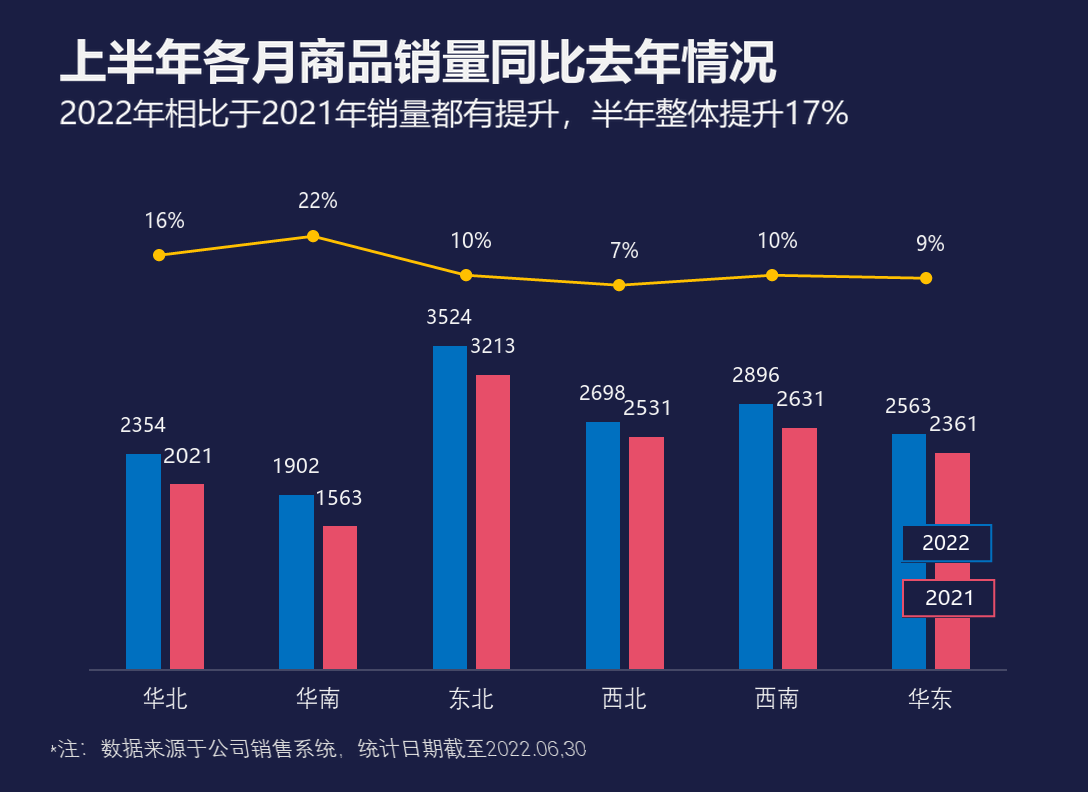

In [7]:
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
W,H,S = 1088,792,4
N,WT,GY,NT,AX = (26,30,67),(255,255,255),(242,242,242),(217,217,217),(69,72,102)
P='C:/Windows/Fonts/'
fp=lambda n:next((p for p in [P+n,'/System/Library/Fonts/PingFang.ttc','/usr/share/fonts/truetype/wqy/wqy-microhei.ttc'] if Path(p).exists()),P+n)
BD,RG,LT,DG,NM=[fp(f) for f in ('msyhbd.ttc','msyh.ttc','msyhl.ttc','Deng.ttf','msyh.ttc')]
F=lambda p,s:ImageFont.truetype(p,s)
im=Image.new('RGB',(W*S,H*S),N);d=ImageDraw.Draw(im)
def R(x0,y0,x1,y1,c):d.rectangle([x0*S,y0*S,(x1+1)*S-1,(y1+1)*S-1],fill=c)
def E(x0,y0,x1,y1,c,o=None,w=1):d.ellipse([x0*S,y0*S,x1*S,y1*S],fill=c,outline=o,width=w*S)
def Q(x0,y0,x1,y1,r,c):d.rounded_rectangle([x0*S,y0*S,(x1+1)*S-1,(y1+1)*S-1],radius=r*S,fill=c)
def L(pts,c,w):d.line([(x*S,y*S) for x,y in pts],fill=c,width=w*S,joint='curve')
def T(s,b,f,z,c,sh=0):
    t=Image.new('RGBA',(1700,160),(0,0,0,0));ImageDraw.Draw(t).text((10,0),s,font=F(f,z),fill=(*c,255))
    t=t.crop(t.getchannel('A').getbbox())
    if sh:t=t.transform((t.width+int(sh*t.height)+4,t.height),Image.AFFINE,(1,-sh,sh*t.height,0,1,0),Image.BICUBIC)
    x0,y0,x1,y1=b;t=t.resize((x1-x0+1,y1-y0+1),Image.LANCZOS);out.paste(t,(x0,y0),t)

R(89,669,1006,670,AX)
B,RD,Y=(0,112,192),(231,78,105),(255,192,0)
for (x0,x1),y in zip([(126,160),(279,313),(433,466),(586,619),(739,772),(892,925)],[454,495,346,422,404,434]):R(x0,y,x1,668,B)
for (x0,x1),y in zip([(170,203),(323,356),(476,509),(629,663),(782,816),(935,969)],[484,526,375,437,428,453]):R(x0,y,x1,668,RD)
L([(159,255),(313,236),(466,275),(619,285),(772,275),(926,278)],Y,3)
for x,y in [(159,255),(313,236),(466,275),(619,285),(772,275),(926,278)]:E(x-6,y-6,x+6,y+6,Y)
R(901,524,992,562,N);d.rectangle([901*S,524*S,992*S,562*S],outline=B,width=2*S)
R(902,579,995,617,N);d.rectangle([902*S,579*S,995*S,617*S],outline=RD,width=2*S)
out=im.resize((W,H),Image.BOX)
T('上半年各月商品销量同比去年情况',(60,38,776,83),BD,45,GY)
T('2022年相比于2021年销量都有提升，半年整体提升17%',(60,98,848,128),RG,26,GY)
for s,b in zip(['16%','22%','10%','7%','10%','9%'],[(146,212,183,227),(299,192,336,207),(452,232,490,247),(611,242,637,257),(759,232,796,247),(917,235,943,250)]):T(s,b,NM,20,GY)
for s,b in zip(['2354','1902','3524','2698','2896','2563'],[(121,417,165,431),(274,458,318,472),(427,309,471,323),(580,385,624,399),(733,367,778,381),(886,398,930,412)]):T(s,b,NM,20,GY)
for s,b in zip(['2021','1563','3213','2531','2631','2361'],[(164,448,209,462),(317,490,361,504),(471,338,514,352),(624,400,668,414),(777,391,821,405),(930,416,974,430)]):T(s,b,NM,20,GY)
T('2022',(923,535,968,549),RG,22,WT);T('2021',(926,590,971,604),RG,22,WT)
for s,b in zip(['华北','华南','东北','西北','西南','华东'],[(143,687,187,708),(296,687,339,708),(449,687,493,709),(602,687,646,708),(755,687,798,708),(908,687,951,709)]):T(s,b,DG,24,GY)
T('*注：数据来源于公司销售系统，统计日期截至2022.06,30',(51,738,593,758),DG,21,NT,0.16)
out.save('chart2.png');display(out)


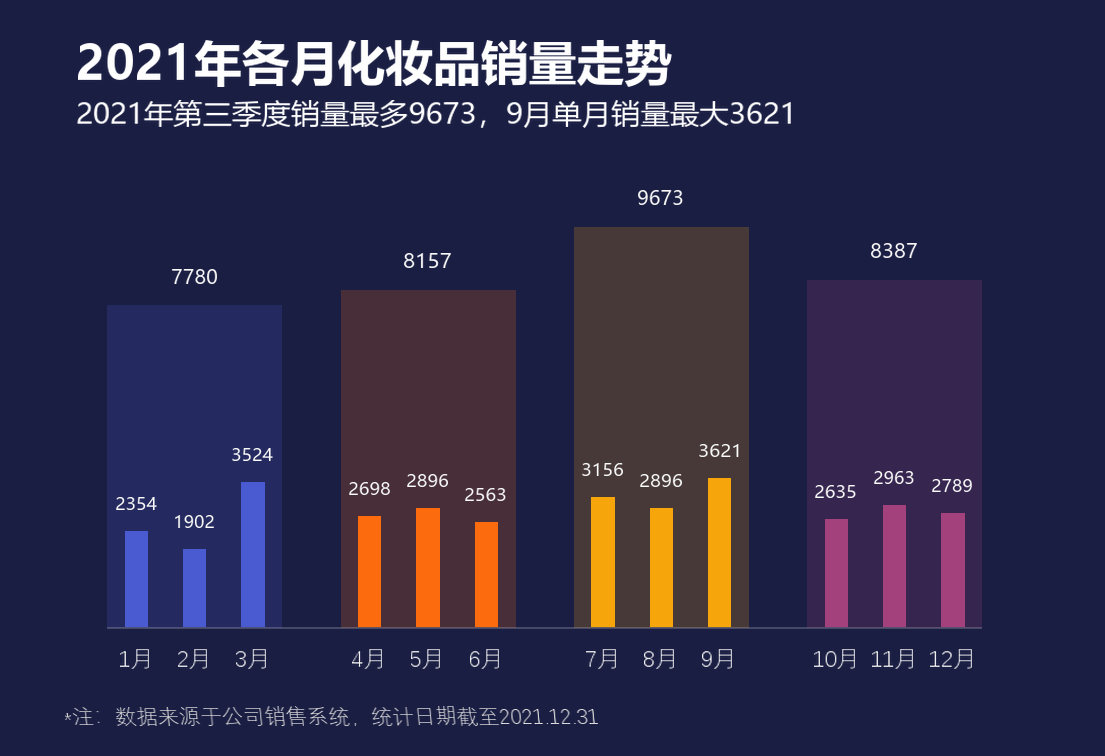

In [8]:
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
W,H,S = 1105,756,4
N,WT,GY,NT,AX = (26,30,67),(255,255,255),(242,242,242),(217,217,217),(69,72,102)
P='C:/Windows/Fonts/'
fp=lambda n:next((p for p in [P+n,'/System/Library/Fonts/PingFang.ttc','/usr/share/fonts/truetype/wqy/wqy-microhei.ttc'] if Path(p).exists()),P+n)
BD,RG,LT,DG,NM=[fp(f) for f in ('msyhbd.ttc','msyh.ttc','msyhl.ttc','Dengl.ttf','msyh.ttc')]
F=lambda p,s:ImageFont.truetype(p,s)
im=Image.new('RGB',(W*S,H*S),N);d=ImageDraw.Draw(im)
def R(x0,y0,x1,y1,c):d.rectangle([x0*S,y0*S,(x1+1)*S-1,(y1+1)*S-1],fill=c)
def E(x0,y0,x1,y1,c,o=None,w=1):d.ellipse([x0*S,y0*S,x1*S,y1*S],fill=c,outline=o,width=w*S)
def Q(x0,y0,x1,y1,r,c):d.rounded_rectangle([x0*S,y0*S,(x1+1)*S-1,(y1+1)*S-1],radius=r*S,fill=c)
def L(pts,c,w):d.line([(x*S,y*S) for x,y in pts],fill=c,width=w*S,joint='curve')
def T(s,b,f,z,c,sh=0):
    t=Image.new('RGBA',(1700,160),(0,0,0,0));ImageDraw.Draw(t).text((10,0),s,font=F(f,z),fill=(*c,255))
    t=t.crop(t.getchannel('A').getbbox())
    if sh:t=t.transform((t.width+int(sh*t.height)+4,t.height),Image.AFFINE,(1,-sh,sh*t.height,0,1,0),Image.BICUBIC)
    x0,y0,x1,y1=b;t=t.resize((x1-x0+1,y1-y0+1),Image.LANCZOS);out.paste(t,(x0,y0),t)

AX=(69,72,102)
for (x0,y0,x1,y1),c in zip([(107,305,281,626),(341,290,515,626),(574,227,748,626),(807,280,981,626)],[(36,42,96),(71,46,57),(70,57,56),(53,37,79)]):R(x0,y0,x1,y1,c)
CL=[(74,91,209)]*3+[(252,108,15)]*3+[(246,165,11)]*3+[(162,65,123)]*3
for (x0,y0,x1),c in zip([(125,531,147),(183,549,205),(241,482,264),(358,516,380),(416,508,439),(475,522,497),(591,497,614),(650,508,672),(708,478,730),(825,519,847),(883,505,905),(941,513,964)],CL):R(x0,y0,x1,626,c)
R(107,627,981,628,AX)
for (x0,x1),c in zip([(107,281),(341,515),(574,748),(807,981)],[(77,82,125),(105,85,94),(104,94,93),(90,78,111)]):R(x0,627,x1,627,c)
out=im.resize((W,H),Image.BOX)
T('2021年各月化妆品销量走势',(78,40,671,86),BD,47,WT)
T('2021年第三季度销量最多9673，9月单月销量最大3621',(77,100,790,127),RG,26,WT)
for s,b in zip(['7780','8157','9673','8387'],[(172,269,216,283),(404,253,450,267),(638,190,682,204),(871,243,916,257)]):T(s,b,NM,22,GY)
for s,b in zip(['2354','1902','3524','2698','2896','2563','3156','2896','3621','2635','2963','2789'],[(116,497,156,509),(175,515,213,527),(232,448,272,460),(349,482,389,494),(407,474,447,486),(465,488,505,500),(582,463,622,475),(640,474,681,486),(699,444,738,456),(815,485,855,497),(874,471,913,483),(932,479,971,491)]):T(s,b,NM,22,GY)
for s,b in zip(['1月','2月','3月','4月','5月','6月','7月','8月','9月','10月','11月','12月'],[(120,649,148,668),(178,649,206,668),(236,649,265,668),(352,649,381,668),(411,649,439,668),(470,649,498,668),(586,649,615,668),(644,649,673,668),(702,649,731,668),(814,649,854,668),(872,649,912,668),(930,649,971,668)]):T(s,b,DG,20,GY)
T('*注：数据来源于公司销售系统，统计日期截至2021.12.31',(65,706,603,725),DG,21,NT,0.10)
out.save('chart3.png');display(out)


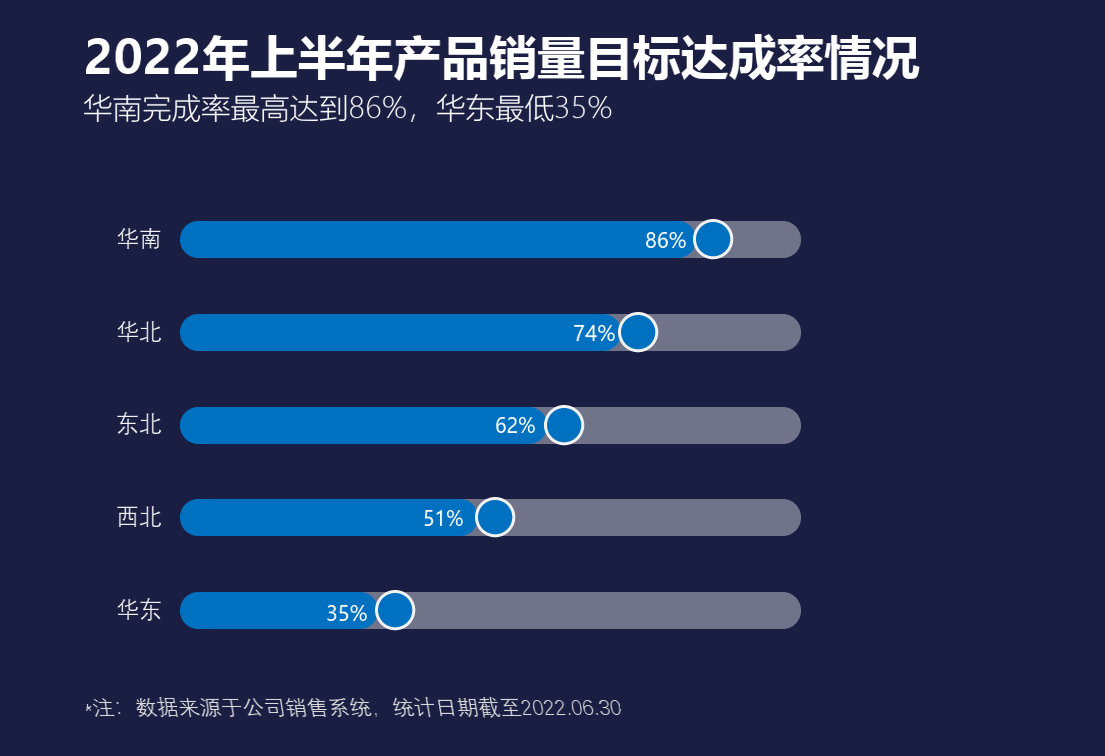

In [9]:
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
W,H,S = 1105,756,4
N,WT,GY,NT,AX = (26,30,67),(255,255,255),(242,242,242),(217,217,217),(69,72,102)
P='C:/Windows/Fonts/'
fp=lambda n:next((p for p in [P+n,'/System/Library/Fonts/PingFang.ttc','/usr/share/fonts/truetype/wqy/wqy-microhei.ttc'] if Path(p).exists()),P+n)
BD,RG,LT,DG,NM=[fp(f) for f in ('msyhbd.ttc','msyh.ttc','msyhl.ttc','Deng.ttf','msyh.ttc')]
F=lambda p,s:ImageFont.truetype(p,s)
im=Image.new('RGB',(W*S,H*S),N);d=ImageDraw.Draw(im)
def R(x0,y0,x1,y1,c):d.rectangle([x0*S,y0*S,(x1+1)*S-1,(y1+1)*S-1],fill=c)
def E(x0,y0,x1,y1,c,o=None,w=1):d.ellipse([x0*S,y0*S,x1*S,y1*S],fill=c,outline=o,width=w*S)
def Q(x0,y0,x1,y1,r,c):d.rounded_rectangle([x0*S,y0*S,(x1+1)*S-1,(y1+1)*S-1],radius=r*S,fill=c)
def L(pts,c,w):d.line([(x*S,y*S) for x,y in pts],fill=c,width=w*S,joint='curve')
def T(s,b,f,z,c,sh=0):
    t=Image.new('RGBA',(1700,160),(0,0,0,0));ImageDraw.Draw(t).text((10,0),s,font=F(f,z),fill=(*c,255))
    t=t.crop(t.getchannel('A').getbbox())
    if sh:t=t.transform((t.width+int(sh*t.height)+4,t.height),Image.AFFINE,(1,-sh,sh*t.height,0,1,0),Image.BICUBIC)
    x0,y0,x1,y1=b;t=t.resize((x1-x0+1,y1-y0+1),Image.LANCZOS);out.paste(t,(x0,y0),t)

B,GR,WH=(0,112,192),(113,115,137),(242,242,242)
Y0=[221,314,407,499,592];CX=[713,638,564,495,395]
for y,cx in zip(Y0,CX):
    Q(180,y,800,y+36,18,GR);Q(180,y,cx-18,y+36,18,B)
    E(cx-20,y-2,cx+20,y+38,B,WH,3)
out=im.resize((W,H),Image.BOX)
T('2022年上半年产品销量目标达成率情况',(86,34,919,80),BD,47,WT)
T('华南完成率最高达到86%，华东最低35%',(84,94,611,121),LT,30,WT)
for s,b in zip(['华南','华北','东北','西北','华东'],[(117,228,160,248),(117,321,161,341),(117,412,161,434),(117,506,161,526),(117,598,160,620)]):T(s,b,DG,24,GY)
for s,b in zip(['86%','74%','62%','51%','35%'],[(646,232,685,247),(574,325,614,340),(496,417,534,432),(424,510,462,525),(327,605,366,620)]):T(s,b,NM,22,WT)
T('*注：数据来源于公司销售系统，统计日期截至2022.06.30',(86,697,628,717),DG,21,NT,0.16)
out.save('chart4.png');display(out)


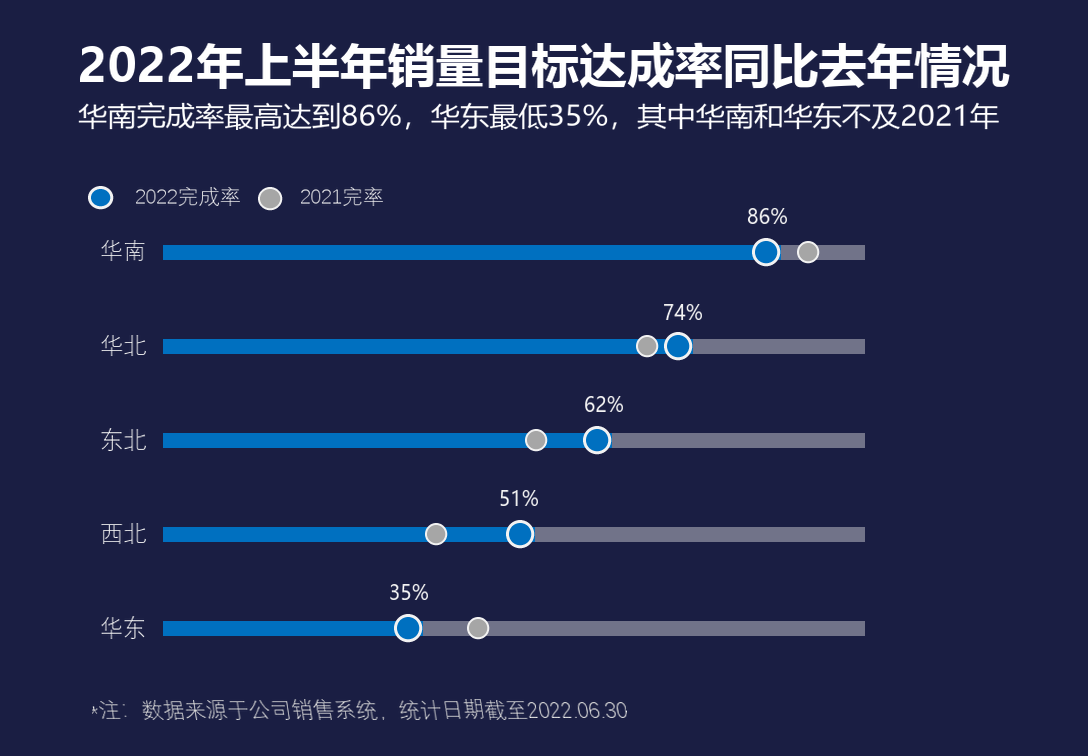

In [10]:
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
W,H,S = 1088,756,4
N,WT,GY,NT,AX = (26,30,67),(255,255,255),(242,242,242),(217,217,217),(69,72,102)
P='C:/Windows/Fonts/'
fp=lambda n:next((p for p in [P+n,'/System/Library/Fonts/PingFang.ttc','/usr/share/fonts/truetype/wqy/wqy-microhei.ttc'] if Path(p).exists()),P+n)
BD,RG,LT,DG,NM=[fp(f) for f in ('msyhbd.ttc','msyh.ttc','msyhl.ttc','Dengl.ttf','msyh.ttc')]
F=lambda p,s:ImageFont.truetype(p,s)
im=Image.new('RGB',(W*S,H*S),N);d=ImageDraw.Draw(im)
def R(x0,y0,x1,y1,c):d.rectangle([x0*S,y0*S,(x1+1)*S-1,(y1+1)*S-1],fill=c)
def E(x0,y0,x1,y1,c,o=None,w=1):d.ellipse([x0*S,y0*S,x1*S,y1*S],fill=c,outline=o,width=w*S)
def Q(x0,y0,x1,y1,r,c):d.rounded_rectangle([x0*S,y0*S,(x1+1)*S-1,(y1+1)*S-1],radius=r*S,fill=c)
def L(pts,c,w):d.line([(x*S,y*S) for x,y in pts],fill=c,width=w*S,joint='curve')
def T(s,b,f,z,c,sh=0):
    t=Image.new('RGBA',(1700,160),(0,0,0,0));ImageDraw.Draw(t).text((10,0),s,font=F(f,z),fill=(*c,255))
    t=t.crop(t.getchannel('A').getbbox())
    if sh:t=t.transform((t.width+int(sh*t.height)+4,t.height),Image.AFFINE,(1,-sh,sh*t.height,0,1,0),Image.BICUBIC)
    x0,y0,x1,y1=b;t=t.resize((x1-x0+1,y1-y0+1),Image.LANCZOS);out.paste(t,(x0,y0),t)

B,GR,WH,GG=(0,112,192),(113,115,137),(242,242,242),(166,166,166)
Y0=[245,339,433,527,621];CX=[766,678,597,520,408];GX=[808,647,536,436,478]
for y,cx,gx in zip(Y0,CX,GX):
    R(163,y,864,y+14,GR);R(163,y,cx+14,y+14,B)
    E(cx-14,y-7,cx+14,y+21,B,WH,3)
    E(gx-11,y-4,gx+11,y+18,GG,WH,2)
E(88,186,113,209,B,WH,3);E(258,187,282,210,GG,WH,2)
out=im.resize((W,H),Image.BOX)
T('2022年上半年销量目标达成率同比去年情况',(80,42,1009,88),BD,47,WT)
T('华南完成率最高达到86%，华东最低35%，其中华南和华东不及2021年',(78,102,998,129),RG,32,WT)
T('2022完成率',(136,187,239,205),DG,24,GY);T('2021完率',(301,187,382,205),DG,24,GY)
for s,b in zip(['华南','华北','东北','西北','华东'],[(101,240,144,260),(101,335,145,355),(101,428,145,450),(101,523,145,543),(101,616,144,638)]):T(s,b,DG,24,GY)
for s,b in zip(['86%','74%','62%','51%','35%'],[(747,208,786,223),(664,304,701,319),(585,396,622,411),(500,490,537,505),(390,584,427,599)]):T(s,b,NM,20,GY)
T('*注：数据来源于公司销售系统，统计日期截至2022.06.30',(92,699,634,719),DG,21,NT,0.16)
out.save('chart5.png');display(out)
